## Libraries

In [2]:
from utils.data_loader import load_mnist
from utils.plots import plot_sample_images, plot_training_history
from utils.models import build_mlp

## Loading MNIST dataset

In [3]:
(X_train_mlp_mnist, y_train_mlp_mnist), (X_test_mlp_mnist, y_test_mlp_mnist) = load_mnist(flatten=True)
print(f"X_train: {X_train_mlp_mnist.shape}, y_train: {y_train_mlp_mnist.shape}")
print(f"X_test: {X_test_mlp_mnist.shape}, y_test: {y_test_mlp_mnist.shape}")

X_train: (60000, 784), y_train: (60000, 10)
X_test: (10000, 784), y_test: (10000, 10)


## Show MNIST dataset images 

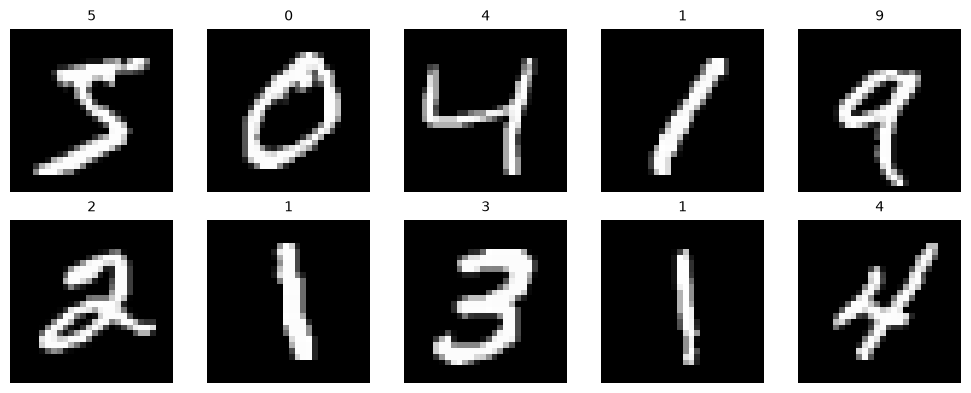

In [4]:
plot_sample_images(X_train_mlp_mnist[:10], y_train_mlp_mnist[:10])


## Model implementation and training

In [5]:
mlp_model = build_mlp(input_shape=(784,), hidden_units=[128, 64], num_classes=10)
mlp_model.summary()

E0000 00:00:1791674807.650063   33767 cuda_platform.cc:52] failed call to cuInit: INTERNAL: CUDA error: Failed call to cuInit: UNKNOWN ERROR (303)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 128)            │       100,480 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 10)             │           650 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 109,386 (427.29 KB)

 Trainable params: 109,386 (427.29 KB)

 Non-trainable params: 0 (0.00 B)

In [6]:
# Entraînement
history_mlp = mlp_model.fit(
    X_train_mlp_mnist, 
    y_train_mlp_mnist,
    validation_data=(X_test_mlp_mnist, y_test_mlp_mnist),
    epochs=10,
    batch_size=64
)

Epoch 1/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 8s 6ms/step - accuracy: 0.9216 - loss: 0.2724 - val_accuracy: 0.9590 - val_loss: 0.1381
Epoch 2/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 6ms/step - accuracy: 0.9668 - loss: 0.1111 - val_accuracy: 0.9668 - val_loss: 0.1030
Epoch 3/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 6s 6ms/step - accuracy: 0.9757 - loss: 0.0791 - val_accuracy: 0.9730 - val_loss: 0.0849
Epoch 4/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9814 - loss: 0.0594 - val_accuracy: 0.9739 - val_loss: 0.0797
Epoch 5/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 5ms/step - accuracy: 0.9855 - loss: 0.0459 - val_accuracy: 0.9749 - val_loss: 0.0753
Epoch 6/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 5s 5ms/step - accuracy: 0.9882 - loss: 0.0365 - val_accuracy: 0.9711 - val_loss: 0.0929
Epoch 7/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9908 - loss: 0.0282 - val_accuracy: 0.9770 - val_loss: 0.0751
Epoch 8/10
938/938 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - accuracy: 0.9923 - loss: 0.0239 - val_accuracy: 0.

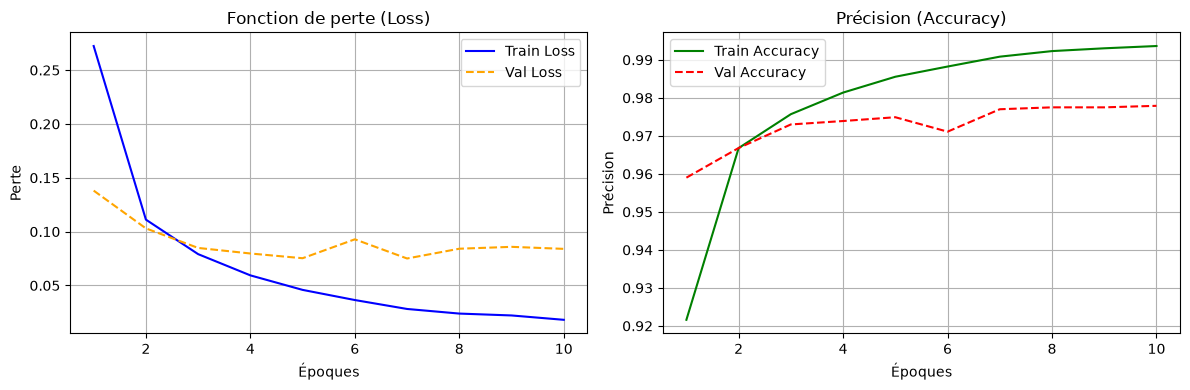

313/313 ━━━━━━━━━━━━━━━━━━━━ 1s 4ms/step - accuracy: 0.9779 - loss: 0.0840
Précision sur le jeu de test : 97.79%


In [7]:

# Courbes d'entraînement
plot_training_history(history_mlp)

test_loss, test_acc = mlp_model.evaluate(X_test_mlp_mnist, y_test_mlp_mnist)
print(f"Précision sur le jeu de test : {test_acc * 100:.2f}%")

In [9]:
mlp_model.save("mlp_mnist.keras")